# Phase 1: Experiment Audit

**Goal:** decide how strongly the data supports causal claims.

The notebook runs from the raw files in this order: load, validate, build the baseline table, create the split, check balance, check timing and leakage, run the placebo test, and only then look at purchase rates.

`target` is read in two places: to stratify the split and, at the end, to compare purchase rates. Nothing before the final section displays it.

Evidence, wording and locked decisions are in `reports/decisions.md`.

## Setup

In [1]:
import hashlib
import os
import re
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import StratifiedKFold, train_test_split
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

TABLES = Path("outputs/tables")
FIGURES = Path("outputs/figures")
PROCESSED = Path("data/processed")
for folder in (TABLES, FIGURES, PROCESSED):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
PRIMARY_CUTOFF = "TIMESTAMP '2019-03-19 00:00:00'"
SENSITIVITY_CUTOFF = "TIMESTAMP '2019-03-12 00:00:00'"
EXPECTED_LABELLED_CUSTOMERS = 200_039
Z_95 = stats.norm.ppf(0.975)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_rows", 200, "display.max_colwidth", 70)

con = duckdb.connect()
con.execute(
    "SET memory_limit='5GB'; SET preserve_insertion_order=false; "
    "SET temp_directory='data/processed/.duckdb_tmp'"
)


def query(sql):
    return con.execute(sql).fetchdf()


def run_sql_file(path):
    con.execute(Path(path).read_text(encoding="utf-8"))

In [2]:
def standardised_mean_difference(treated, control):
    treated, control = np.asarray(treated, float), np.asarray(control, float)
    treated, control = treated[~np.isnan(treated)], control[~np.isnan(control)]
    pooled_sd = np.sqrt((treated.var(ddof=1) + control.var(ddof=1)) / 2)
    return (treated.mean() - control.mean()) / pooled_sd


def smd_status(smd):
    if np.isnan(smd):
        return "Not computable"
    size = abs(smd)
    return "Concern" if size > 0.1 else "Review" if size > 0.05 else "Below 0.05"


def difference_in_rates(treated_events, treated_n, control_events, control_n):
    treated_rate, control_rate = treated_events / treated_n, control_events / control_n
    difference = treated_rate - control_rate
    se = np.sqrt(treated_rate * (1 - treated_rate) / treated_n + control_rate * (1 - control_rate) / control_n)
    return {
        "treated_rate": treated_rate,
        "control_rate": control_rate,
        "difference": difference,
        "ci_low": difference - Z_95 * se,
        "ci_high": difference + Z_95 * se,
    }


# Known-answer checks for the statistics helpers.
assert np.isclose(standardised_mean_difference([1, 2, 3], [2, 3, 4]), -1.0)
assert np.isclose(standardised_mean_difference([1, 1, 0, 0], [1, 0, 0, 0]), 0.25 / np.sqrt((1 / 3 + 1 / 4) / 2))
assert np.isclose(standardised_mean_difference([1, np.nan, 3], [1, 3]), 0.0)
assert (smd_status(0.049), smd_status(-0.07), smd_status(0.11)) == ("Below 0.05", "Review", "Concern")
assert smd_status(float("nan")) == "Not computable"
_known = difference_in_rates(60, 100, 50, 100)
assert np.isclose(_known["difference"], 0.1)
assert np.isclose(_known["ci_high"] - _known["difference"], Z_95 * 0.07)

## 1. Data checks

Load the raw files to typed Parquet, then run the validation queries. Any check with a hard expectation stops the notebook if it fails.

In [3]:
# The loader binds columns by position, so a reordered file would otherwise load with wrong labels.
EXPECTED_HEADERS = {
    "clients.csv": "client_id,first_issue_date,first_redeem_date,age,gender",
    "uplift_train.csv": "client_id,treatment_flg,target",
    "uplift_test.csv": "client_id",
    "products.csv": "product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol",
    "purchases.csv": (
        "client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,"
        "regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,"
        "trn_sum_from_iss,trn_sum_from_red"
    ),
}
for file_name, expected_header in EXPECTED_HEADERS.items():
    with open(Path("data/raw") / file_name, encoding="utf-8") as raw_file:
        header = raw_file.readline().strip()
    assert header == expected_header, f"Unexpected columns in {file_name}: {header}"

run_sql_file("sql/00_load_to_parquet.sql")
run_sql_file("sql/01_data_validation.sql")

data_quality = query("SELECT * FROM data_quality ORDER BY check_group, check_name")
data_quality.to_csv(TABLES / "data_quality.csv", index=False)
failed_checks = data_quality[data_quality["status"] == "FAIL"]
assert failed_checks.empty, f"Data quality checks failed: {failed_checks['check_name'].tolist()}"
data_quality

,check_group,check_name,value,expected,status
0,Invalid values,clients with age outside 14-100,1779.0,NaN,REPORT
1,Invalid values,first_redeem_date before first_issue_date,536.0,NaN,REPORT
2,Invalid values,"gender outside M, F, U",0.0,0.0,PASS
3,Invalid values,maximum age,1901.0,NaN,REPORT
4,Invalid values,minimum age,-7491.0,NaN,REPORT
5,Invalid values,negative purchase_sum,0.0,0.0,PASS
6,Invalid values,purchase rows with negative quantity,0.0,0.0,PASS
7,Invalid values,purchase rows with zero quantity,2707278.0,NaN,REPORT
8,Invalid values,transactions dated on or after the primary cutoff,0.0,0.0,PASS
9,Invalid values,transactions with a zero-quantity row,1829319.0,NaN,REPORT


In [4]:
missing_values = query("SELECT * FROM data_quality_missing ORDER BY source, column_name")
missing_values["share_missing"] = missing_values["n_missing"] / missing_values["n_rows"]
missing_values.to_csv(TABLES / "data_quality_missing.csv", index=False)
missing_values[missing_values["n_missing"] > 0]

,source,column_name,n_missing,n_rows,share_missing
3,clients,first_redeem_date,35469,400162,0.088637
5,products,brand_id,5200,43038,0.120823
8,products,level_1,3,43038,0.000070
9,products,level_2,3,43038,0.000070
10,products,level_3,3,43038,0.000070
11,products,level_4,3,43038,0.000070
12,products,netto,3,43038,0.000070
14,products,segment_id,1572,43038,0.036526
15,products,vendor_id,34,43038,0.000790
28,purchases,trn_sum_from_red,42743212,45786568,0.933532


In [5]:
date_ranges = query("SELECT * FROM data_quality_dates ORDER BY date_column")
date_ranges.to_csv(TABLES / "data_quality_dates.csv", index=False)
date_ranges

,date_column,earliest,latest
0,first_issue_date,2017-04-04 18:24:18,2019-03-15 21:50:56
1,first_redeem_date,2017-04-11 09:42:20,2019-11-20 01:14:10
2,transaction_datetime,2018-11-21 21:02:33,2019-03-18 23:40:03


In [6]:
amount_reconciliation = query("SELECT * FROM amount_reconciliation ORDER BY has_sum_from_red, points_spent")
amount_reconciliation.to_csv(TABLES / "amount_reconciliation.csv", index=False)
amount_reconciliation

,has_sum_from_red,points_spent,n_transactions,share_within_1_iss_plus_red,share_within_1_iss_only,median_gap,mean_gap,total_purchase_sum,total_sum_from_iss,total_sum_from_red
0,False,False,7538988,0.571987,0.571987,-0.14,6.002342,3.208352e+09,3.163101e+09,0.0
1,False,True,5,0.000000,0.000000,30.00,29.800000,1.193000e+03,1.044000e+03,0.0
2,True,False,1644,0.000608,0.534672,-192.50,-321.595620,5.429818e+05,5.353240e+05,536361.0
3,True,True,504592,0.021516,0.012959,-228.01,-393.901350,2.354974e+08,2.011424e+08,233114475.0


`purchase_sum` holds one value per `(client_id, transaction_id)`, so it is safe at transaction level. The product-level amounts do not reconcile with it, and in redemption transactions `trn_sum_from_iss` and `trn_sum_from_red` are not additive. This is documented and not repaired. `purchase_sum` is the only monetary measure.

## 2. Baseline customer table

One row per labelled customer at the primary cutoff and at the seven-day sensitivity cutoff. No customer is dropped.

In [7]:
baseline = query(f"SELECT * FROM baseline_customers({PRIMARY_CUTOFF})")
baseline_sensitivity = query(f"SELECT * FROM baseline_customers({SENSITIVITY_CUTOFF})")

for table in (baseline, baseline_sensitivity):
    assert len(table) == EXPECTED_LABELLED_CUSTOMERS
    assert table["client_id"].is_unique
    assert table["age"].dropna().between(14, 100).all()
    assert "target" not in table.columns

# Spend is recomputed from the product-level rows, independently of the transactions table,
# so double counted product rows or a wrong transaction key would fail here.
for table, cutoff in ((baseline, PRIMARY_CUTOFF), (baseline_sensitivity, SENSITIVITY_CUTOFF)):
    expected_spend = query(
        f"""
        SELECT sum(purchase_sum) AS total
        FROM (
            SELECT DISTINCT client_id, transaction_id, purchase_sum
            FROM purchases
            WHERE transaction_datetime < {cutoff}
        )
        JOIN customer_groups USING (client_id)
        """
    )["total"].iloc[0]
    assert np.isclose(table["total_spend"].sum(), expected_spend, rtol=1e-9)

baseline.to_parquet(PROCESSED / "baseline_customers.parquet", index=False)
pd.DataFrame(
    {
        "primary cutoff": baseline[["age_invalid_flg", "pre_issue_purchase_flg"]].sum(),
        "sensitivity cutoff": baseline_sensitivity[["age_invalid_flg", "pre_issue_purchase_flg"]].sum(),
    }
)

,primary cutoff,sensitivity cutoff
age_invalid_flg,883,883
pre_issue_purchase_flg,23532,23378


In [8]:
print("Customers at both cutoffs:", len(baseline))
print("Primary cutoff: longest days since last purchase:", int(baseline["days_since_last_purchase"].max()))
print("Sensitivity cutoff: customers with no earlier purchase:", int((baseline_sensitivity["transaction_count"] == 0).sum()))
print("Sensitivity cutoff: cards issued after the cutoff:", int(baseline_sensitivity["days_since_first_issue"].isna().sum()))

Customers at both cutoffs: 200039
Primary cutoff: longest days since last purchase: 22
Sensitivity cutoff: customers with no earlier purchase: 753
Sensitivity cutoff: cards issued after the cutoff: 154


## 3. Permanent split

Sorted by `client_id`, seed 42, stratified on the four treatment by target groups. The hash covers the sorted customer IDs with their split and fold labels and must match the value in `reports/decisions.md`.

The assertions check stratification without displaying any stratum counts, so purchase rates stay unseen.

In [9]:
labelled = query(
    "SELECT client_id, treatment_flg, target FROM 'data/processed/uplift_train.parquet' ORDER BY client_id"
)
strata = labelled["treatment_flg"].to_numpy() * 2 + labelled["target"].to_numpy()
assert len(labelled) == EXPECTED_LABELLED_CUSTOMERS

positions = np.arange(len(labelled))
development_positions, holdout_positions = train_test_split(
    positions, test_size=0.2, stratify=strata, random_state=SEED
)

folds = np.full(len(labelled), -1)
fold_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold_number, (_, validation) in enumerate(
    fold_splitter.split(development_positions, strata[development_positions]), start=1
):
    folds[development_positions[validation]] = fold_number

splits = pd.DataFrame({"client_id": labelled["client_id"], "split": "development", "fold": folds})
splits.loc[holdout_positions, "split"] = "holdout"
splits["fold"] = splits["fold"].astype("Int8").mask(splits["split"] == "holdout")

# Every customer is assigned once, and each stratum is split evenly.
assert splits["client_id"].is_unique and len(splits) == len(labelled)
assert (splits["split"] == "holdout").sum() in {len(labelled) // 5, len(labelled) // 5 + 1}
assert splits.loc[splits["split"] == "development", "fold"].notna().all()
assert splits.loc[splits["split"] == "holdout", "fold"].isna().all()
for stratum in np.unique(strata):
    in_stratum = strata == stratum
    holdout_count = (splits["split"].to_numpy()[in_stratum] == "holdout").sum()
    assert abs(holdout_count - in_stratum.sum() * 0.2) <= 1, "Holdout is not evenly stratified"
    fold_counts = splits.loc[in_stratum, "fold"].value_counts()
    assert len(fold_counts) == 5 and fold_counts.max() - fold_counts.min() <= 1, "Folds are not evenly stratified"

canonical = "".join(
    f"{client},{split},{'' if pd.isna(fold) else int(fold)}\n"
    for client, split, fold in zip(splits["client_id"], splits["split"], splits["fold"])
)
split_hash = hashlib.sha256(canonical.encode("utf-8")).hexdigest()

recorded = re.search(r"\*\*Split SHA-256:\*\* `([0-9a-f]{64})`", Path("reports/decisions.md").read_text(encoding="utf-8"))
assert recorded, f"No split hash recorded in reports/decisions.md. This run produced {split_hash}"
assert split_hash == recorded.group(1), f"Split changed: {split_hash} differs from {recorded.group(1)}"

splits.to_parquet(PROCESSED / "splits.parquet", index=False)
del labelled, strata

print("Split hash matches reports/decisions.md:", split_hash)
print(splits["split"].value_counts().to_string())
print(splits["fold"].value_counts().sort_index().to_string())

Split hash matches reports/decisions.md: 20d8b8e1ea2d348e6c8f83cf5a92cd421761fa612429d23efd8720279a66c223
split
development    160031
holdout         40008
fold
1    32007
2    32006
3    32006
4    32006
5    32006


## 4. Group comparability

Balance supports the assignment wording but does not prove randomisation. At this sample size p-values flag very small differences, so the review uses standardised mean differences (SMD).

In [10]:
treated_n = int((baseline["treatment_flg"] == 1).sum())
control_n = int((baseline["treatment_flg"] == 0).sum())
n_total = treated_n + control_n

sample_ratio = pd.DataFrame(
    [
        {
            "treated": treated_n,
            "control": control_n,
            "treated_share": treated_n / n_total,
            "chi_square_p": stats.chisquare([treated_n, control_n]).pvalue,
            "exact_binomial_p": stats.binomtest(treated_n, n_total, 0.5).pvalue,
        }
    ]
)
sample_ratio.to_csv(TABLES / "sample_ratio_check.csv", index=False)
sample_ratio

,treated,control,treated_share,chi_square_p,exact_binomial_p
0,99981,100058,0.499808,0.863311,0.865069


In [11]:
def balance_columns(table):
    columns = pd.DataFrame(
        {
            "treatment_flg": table["treatment_flg"],
            "Age (valid values)": table["age"].astype(float),
            "Invalid age": table["age_invalid_flg"],
            "Gender: F": (table["gender"] == "F").astype(int),
            "Gender: M": (table["gender"] == "M").astype(int),
            "Gender: U": (table["gender"] == "U").astype(int),
            "Days since first issue": table["days_since_first_issue"].astype(float),
            "Purchase before issue": table["pre_issue_purchase_flg"],
            "Transaction count": table["transaction_count"],
            "Transaction count (log)": np.log1p(table["transaction_count"]),
            "Total spend": table["total_spend"],
            "Total spend (log)": np.log1p(table["total_spend"]),
            "Days since last purchase": table["days_since_last_purchase"].astype(float),
        }
    )
    return columns


def balance_table(table):
    columns = balance_columns(table)
    treated = columns[columns["treatment_flg"] == 1]
    control = columns[columns["treatment_flg"] == 0]
    rows = []
    for name in columns.columns.drop("treatment_flg"):
        rows.append(
            {
                "variable": name,
                "treated_mean": treated[name].mean(),
                "control_mean": control[name].mean(),
                "treated_missing": int(treated[name].isna().sum()),
                "control_missing": int(control[name].isna().sum()),
                "smd": standardised_mean_difference(treated[name], control[name]),
            }
        )
    return pd.DataFrame(rows)


balance = balance_table(baseline)
balance["status"] = balance["smd"].map(smd_status)
sensitivity = balance_table(baseline_sensitivity).set_index("variable")
balance["smd_sensitivity_cutoff"] = balance["variable"].map(sensitivity["smd"])
balance["status_sensitivity_cutoff"] = balance["smd_sensitivity_cutoff"].map(smd_status)
balance["treated_missing_sensitivity"] = balance["variable"].map(sensitivity["treated_missing"])
balance["control_missing_sensitivity"] = balance["variable"].map(sensitivity["control_missing"])
balance.to_csv(TABLES / "balance_table.csv", index=False)
assert balance[["smd", "smd_sensitivity_cutoff"]].notna().all().all(), "A balance check could not be computed"

noise_band = Z_95 * np.sqrt(1 / treated_n + 1 / control_n)
print(f"An SMD inside +/-{noise_band:.4f} is within the usual 95% range for a random split of this size.")
print(f"Largest absolute SMD, primary cutoff: {balance['smd'].abs().max():.4f}")
print(f"Largest absolute SMD, sensitivity cutoff: {balance['smd_sensitivity_cutoff'].abs().max():.4f}")
print("Outside that range, primary cutoff:", balance.loc[balance["smd"].abs() > noise_band, "variable"].tolist())
print(
    "Outside that range, sensitivity cutoff:",
    balance.loc[balance["smd_sensitivity_cutoff"].abs() > noise_band, "variable"].tolist(),
)
balance

An SMD inside +/-0.0088 is within the usual 95% range for a random split of this size.
Largest absolute SMD, primary cutoff: 0.0130
Largest absolute SMD, sensitivity cutoff: 0.0129
Outside that range, primary cutoff: ['Purchase before issue', 'Total spend (log)']
Outside that range, sensitivity cutoff: ['Purchase before issue', 'Total spend (log)', 'Days since last purchase']


,variable,treated_mean,control_mean,treated_missing,control_missing,smd,status,smd_sensitivity_cutoff,status_sensitivity_cutoff,treated_missing_sensitivity,control_missing_sensitivity
0,Age (valid values),46.464513,46.378114,451,432,0.005442,Below 0.05,0.005442,Below 0.05,451,432
1,Invalid age,0.004511,0.004317,0,0,0.002917,Below 0.05,0.002917,Below 0.05,0,0
2,Gender: F,0.369180,0.367637,0,0,0.003200,Below 0.05,0.003200,Below 0.05,0,0
3,Gender: M,0.167282,0.167763,0,0,-0.001288,Below 0.05,-0.001288,Below 0.05,0,0
4,Gender: U,0.463538,0.464601,0,0,-0.002130,Below 0.05,-0.002130,Below 0.05,0,0
5,Days since first issue,434.101099,432.359961,0,0,0.008550,Below 0.05,0.008442,Below 0.05,74,80
6,Purchase before issue,0.115542,0.119731,0,0,-0.013001,Below 0.05,-0.012853,Below 0.05,0,0
7,Transaction count,20.185595,20.056097,0,0,0.007303,Below 0.05,0.007500,Below 0.05,0,0
8,Transaction count (log),2.743150,2.736477,0,0,0.008166,Below 0.05,0.008420,Below 0.05,0,0
9,Total spend,8625.699528,8569.366066,0,0,0.006319,Below 0.05,0.006726,Below 0.05,0,0


## 5. Campaign timing and leakage

The primary cutoff is locked. These checks describe the data and cannot move it.

In [12]:
SURFACE, INK, INK_SECONDARY, MUTED, GRIDLINE, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
TREATED_COLOR, CONTROL_COLOR = "#2a78d6", "#eb6834"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRIDLINE,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "lines.linewidth": 1.6,
    }
)


def format_date_axis(axis, interval=14):
    axis.xaxis.set_major_locator(mdates.DayLocator(interval=interval))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

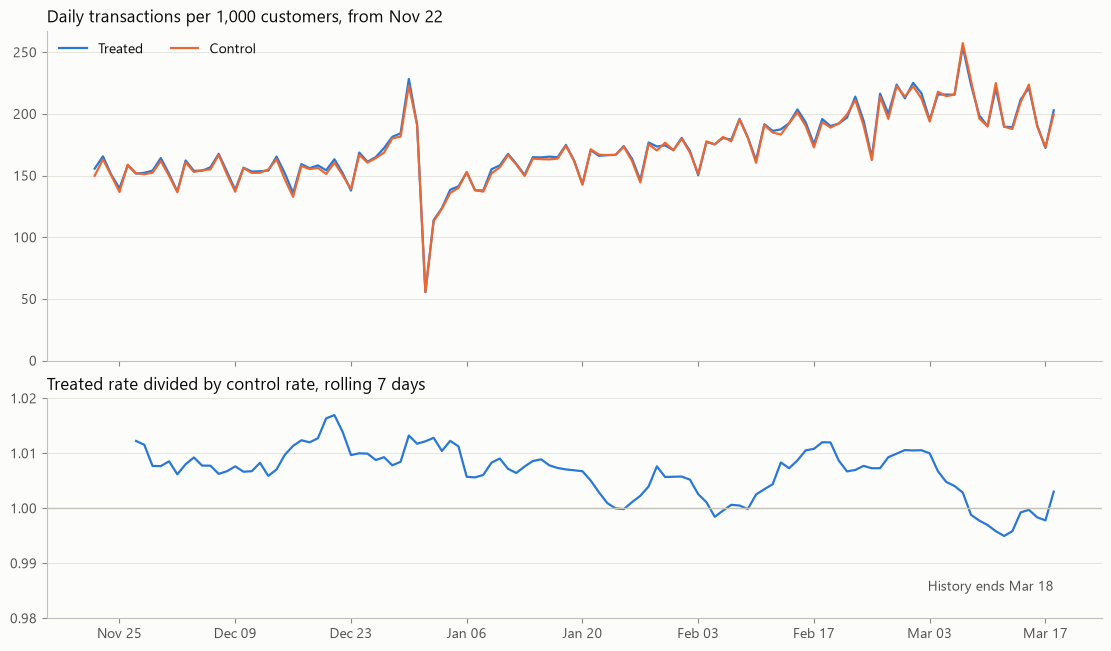

Final 7-day ratio: 1.0030
Range of earlier rolling 7-day ratios: 0.9950 to 1.0169


In [13]:
daily = query("SELECT * FROM daily_activity ORDER BY activity_date, treatment_flg")
daily.to_csv(TABLES / "daily_activity.csv", index=False)

daily_wide = daily.pivot(index="activity_date", columns="treatment_flg", values="n_transactions")
daily_wide.index = pd.to_datetime(daily_wide.index)
rate = pd.DataFrame(
    {
        "treated": daily_wide[1] / treated_n * 1000,
        "control": daily_wide[0] / control_n * 1000,
    }
)
rolling_ratio = (daily_wide[1].rolling(7).sum() / treated_n) / (daily_wide[0].rolling(7).sum() / control_n)

figure, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, height_ratios=[3, 2], layout="constrained")
plotted = rate.iloc[1:]  # The first day (Nov 21) only has late-evening transactions.
top.plot(plotted.index, plotted["treated"], color=TREATED_COLOR, label="Treated")
top.plot(plotted.index, plotted["control"], color=CONTROL_COLOR, label="Control")
top.set_title("Daily transactions per 1,000 customers, from Nov 22")
top.set_ylim(bottom=0)
top.legend(loc="upper left", ncols=2)

bottom.plot(rolling_ratio.index, rolling_ratio, color=TREATED_COLOR)
bottom.axhline(1, color=AXIS, linewidth=1)
bottom.set_title("Treated rate divided by control rate, rolling 7 days")
bottom.set_ylim(0.98, 1.02)
format_date_axis(bottom)
bottom.text(rolling_ratio.index[-1], 0.985, "History ends Mar 18", ha="right", color=INK_SECONDARY)
figure.savefig(FIGURES / "daily_activity.png", dpi=160)
plt.show()

complete_days = rolling_ratio.dropna()
print(f"Final 7-day ratio: {complete_days.iloc[-1]:.4f}")
print(f"Range of earlier rolling 7-day ratios: {complete_days.iloc[:-1].min():.4f} to {complete_days.iloc[:-1].max():.4f}")

In [14]:
redeem = query(f"SELECT * FROM first_redeem_by_group({PRIMARY_CUTOFF})")
redeem["group"] = redeem["treatment_flg"].map({1: "Treated", 0: "Control"})
redeem["share_missing"] = redeem["n_missing"] / redeem["n_customers"]
redeem["share_after_cutoff"] = redeem["n_after_cutoff"] / redeem["n_customers"]
redeem["share_after_cutoff_of_non_missing"] = redeem["n_after_cutoff"] / (redeem["n_customers"] - redeem["n_missing"])
redeem.to_csv(TABLES / "first_redeem_by_group.csv", index=False)
redeem[["group", "n_customers", "share_missing", "share_after_cutoff", "share_after_cutoff_of_non_missing", "latest"]]

,group,n_customers,share_missing,share_after_cutoff,share_after_cutoff_of_non_missing,latest
0,Control,100058,0.091027,0.111036,0.122155,2019-11-19 21:25:41
1,Treated,99981,0.084396,0.114922,0.125515,2019-11-20 01:14:10


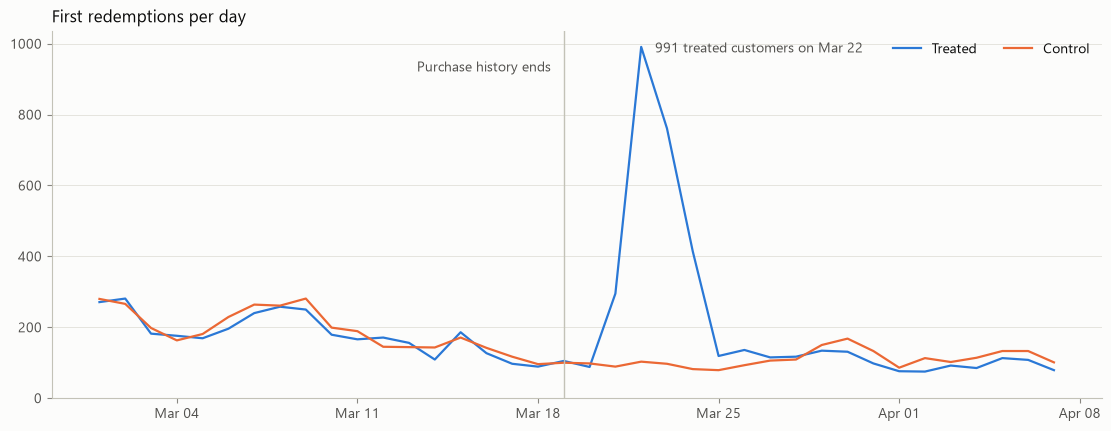

treatment_flg,treated,control
redeem_date,,
2019-03-17,97.0,117.0
2019-03-18,89.0,96.0
2019-03-19,105.0,100.0
2019-03-20,88.0,98.0
2019-03-21,295.0,89.0
2019-03-22,991.0,103.0
2019-03-23,761.0,97.0
2019-03-24,414.0,82.0
2019-03-25,119.0,79.0


In [15]:
redeem_daily = query("SELECT * FROM first_redeem_daily ORDER BY redeem_date, treatment_flg")
redeem_daily.to_csv(TABLES / "first_redeem_daily.csv", index=False)
redeem_wide = redeem_daily.pivot(index="redeem_date", columns="treatment_flg", values="n_customers").fillna(0)
redeem_wide.index = pd.to_datetime(redeem_wide.index)
window = redeem_wide.loc["2019-03-01":"2019-04-07"]

figure, axis = plt.subplots(figsize=(11, 4.2), layout="constrained")
axis.plot(window.index, window[1], color=TREATED_COLOR, label="Treated")
axis.plot(window.index, window[0], color=CONTROL_COLOR, label="Control")
axis.axvline(pd.Timestamp("2019-03-19"), color=AXIS, linewidth=1)
axis.text(pd.Timestamp("2019-03-18 12:00"), window[1].max() * 0.93, "Purchase history ends", ha="right", color=INK_SECONDARY)
peak_date = window[1].idxmax()
axis.annotate(
    f"{int(window[1].max()):,} treated customers on {peak_date:%b %d}",
    xy=(peak_date, window[1].max()),
    xytext=(10, -4),
    textcoords="offset points",
    color=INK_SECONDARY,
)
axis.set_title("First redemptions per day")
axis.set_ylim(bottom=0)
axis.legend(loc="upper right", ncols=2)
format_date_axis(axis, interval=7)
figure.savefig(FIGURES / "first_redeem_daily.png", dpi=160)
plt.show()

window.loc["2019-03-17":"2019-03-26"].rename(columns={1: "treated", 0: "control"})[["treated", "control"]]

### Points fields

Customer-level comparison before the cutoff, with one value per transaction, over the full history and the last 28 days. Regular points are checked the same way because Phase 2 loyalty features will use them.

SMD alone is a weak test for a rare field: when only 0.06% of customers have a value, an SMD below 0.05 still allows a large relative gap. So the "any points" rows also get a risk ratio with a 95% interval. A field passes only if every SMD is below 0.05 and every risk ratio interval includes 1.

In [16]:
POINTS_WINDOWS = {
    "Full history": "TIMESTAMP '2018-11-01 00:00:00'",
    "Last 28 days": "TIMESTAMP '2019-02-19 00:00:00'",
}
POINTS_VARIABLES = {
    "any_express_received": "Any express points received",
    "any_express_spent": "Any express points spent",
    "express_received": "Express points received",
    "express_spent": "Express points spent",
    "any_regular_received": "Any regular points received",
    "any_regular_spent": "Any regular points spent",
    "regular_received": "Regular points received",
    "regular_spent": "Regular points spent",
}

rows = []
for window_name, window_start in POINTS_WINDOWS.items():
    points = query(f"SELECT * FROM customer_points({window_start}, {PRIMARY_CUTOFF})")
    treated, control = points[points["treatment_flg"] == 1], points[points["treatment_flg"] == 0]
    for column, label in POINTS_VARIABLES.items():
        row = {
            "window": window_name,
            "variable": label,
            "treated_mean": treated[column].mean(),
            "control_mean": control[column].mean(),
            "smd": standardised_mean_difference(treated[column], control[column]),
        }
        if column.startswith("any_"):
            x1, n1, x0, n0 = treated[column].sum(), len(treated), control[column].sum(), len(control)
            log_rr = np.log((x1 / n1) / (x0 / n0))
            se = np.sqrt((1 - x1 / n1) / x1 + (1 - x0 / n0) / x0)
            row.update(
                treated_customers_with_value=x1,
                control_customers_with_value=x0,
                risk_ratio=np.exp(log_rr),
                risk_ratio_ci_low=np.exp(log_rr - Z_95 * se),
                risk_ratio_ci_high=np.exp(log_rr + Z_95 * se),
            )
        rows.append(row)
points_balance = pd.DataFrame(rows)
points_balance["status"] = points_balance["smd"].map(smd_status)
points_balance.to_csv(TABLES / "points_balance.csv", index=False)


def field_passes(rows):
    ratios = rows.dropna(subset=["risk_ratio"])
    return bool(
        (rows["smd"].abs() < 0.05).all()
        and ((ratios["risk_ratio_ci_low"] <= 1) & (ratios["risk_ratio_ci_high"] >= 1)).all()
    )


print("Express points pass:", field_passes(points_balance[points_balance["variable"].str.contains("xpress")]))
print("Regular points pass:", field_passes(points_balance[points_balance["variable"].str.contains("egular")]))
points_balance

Express points pass: True
Regular points pass: True


,window,variable,treated_mean,control_mean,smd,treated_customers_with_value,control_customers_with_value,risk_ratio,risk_ratio_ci_low,risk_ratio_ci_high,status
0,Full history,Any express points received,0.018904,0.018199,0.005218,1890.0,1821.0,1.038691,0.974532,1.107074,Below 0.05
1,Full history,Any express points spent,0.181174,0.181165,0.000025,18114.0,18127.0,1.000052,0.981591,1.018861,Below 0.05
2,Full history,Express points received,0.809704,0.783745,0.003391,NaN,NaN,NaN,NaN,NaN,Below 0.05
3,Full history,Express points spent,6.466999,6.441674,0.001553,NaN,NaN,NaN,NaN,NaN,Below 0.05
4,Full history,Any regular points received,0.999250,0.999240,0.000343,99906.0,99982.0,1.000009,0.999769,1.000250,Below 0.05
5,Full history,Any regular points spent,0.605455,0.603240,0.004530,60534.0,60359.0,1.003672,0.996579,1.010814,Below 0.05
6,Full history,Regular points received,78.220580,77.825337,0.004009,NaN,NaN,NaN,NaN,NaN,Below 0.05
7,Full history,Regular points spent,73.509597,73.284665,0.001697,NaN,NaN,NaN,NaN,NaN,Below 0.05
8,Last 28 days,Any express points received,0.000610,0.000520,0.003805,61.0,52.0,1.173980,0.811049,1.699318,Below 0.05
9,Last 28 days,Any express points spent,0.067063,0.066192,0.003493,6705.0,6623.0,1.013161,0.980464,1.046948,Below 0.05


In [17]:
express_weekly = query("SELECT * FROM express_points_weekly ORDER BY week_start, treatment_flg")
express_weekly.to_csv(TABLES / "express_points_weekly.csv", index=False)
express_weekly.pivot(index="week_start", columns="treatment_flg", values="share_received").rename(
    columns={1: "treated_share_received", 0: "control_share_received"}
)

treatment_flg,control_share_received,treated_share_received
week_start,,
2018-11-19,0.000000,0.000000
2018-11-26,0.010556,0.010677
2018-12-03,0.004024,0.004513
2018-12-10,0.000000,0.000000
2018-12-17,0.000000,0.000000
2018-12-24,0.000000,0.000000
2018-12-31,0.000000,0.000000
2019-01-07,0.000000,0.000000
2019-01-14,0.000000,0.000000


## 6. Placebo outcome

Any purchase in a window before the likely campaign start. Rates should not differ between groups beyond chance.

The primary window ends before the 2019-02-24 activity boundary. The secondary window is the plan's original one and overlaps that boundary.

In [18]:
PLACEBO_WINDOWS = {
    "Primary: Jan 27 to Feb 23": ("TIMESTAMP '2019-01-27 00:00:00'", "TIMESTAMP '2019-02-24 00:00:00'"),
    "Secondary: Feb 18 to Mar 3": ("TIMESTAMP '2019-02-18 00:00:00'", "TIMESTAMP '2019-03-04 00:00:00'"),
}

rows = []
for name, (start, end) in PLACEBO_WINDOWS.items():
    counts = query(f"SELECT * FROM placebo_rates({start}, {end})").set_index("treatment_flg")
    assert counts["n_customers"].sum() == EXPECTED_LABELLED_CUSTOMERS
    rows.append(
        {
            "window": name,
            **difference_in_rates(
                counts.loc[1, "n_purchasers"], counts.loc[1, "n_customers"],
                counts.loc[0, "n_purchasers"], counts.loc[0, "n_customers"],
            ),
        }
    )
placebo = pd.DataFrame(rows)
placebo["interval_includes_zero"] = (placebo["ci_low"] <= 0) & (placebo["ci_high"] >= 0)
placebo.to_csv(TABLES / "placebo_outcome.csv", index=False)
placebo

,window,treated_rate,control_rate,difference,ci_low,ci_high,interval_includes_zero
0,Primary: Jan 27 to Feb 23,0.875246,0.874763,0.000484,-0.002415,0.003382,True
1,Secondary: Feb 18 to Mar 3,0.835389,0.833427,0.001962,-0.001296,0.005220,True


## Conclusions recorded before purchase rates

The conclusions were written to `reports/decisions.md` before the next section was first run. Two checks were added after code review, as that log explains; neither changed a conclusion.

- **Sample ratio:** no problem against an expected 50/50 split.
- **Balance:** all 12 variables are below the 0.05 review threshold at both cutoffs. At the primary cutoff, two fall slightly outside the range expected from a random split: purchase before issue (-0.0130) and log total spend (+0.0095). At the sensitivity cutoff, days since last purchase (+0.0121) does too. Balance on observed variables does not prove randomisation.
- **Placebo:** neither window shows a difference, and both intervals include zero.
- **`first_redeem_date`:** contains post-treatment information, so it stays out of all model feature sets.
- **`express_points_*`:** pass on values before the cutoff. The field remains undocumented, and recent values are too rare to rule out a sizeable relative difference.
- **Allowed wording:** "Observed checks are consistent with random assignment, but randomisation is not documented. Causal claims depend on that assumption."

In [19]:
# The text above and reports/decisions.md quote these values, so a change must stop the run.
assert round(balance["smd"].abs().max(), 4) == 0.0130
assert round(balance["smd_sensitivity_cutoff"].abs().max(), 4) == 0.0129
assert set(balance.loc[balance["smd"].abs() > noise_band, "variable"]) == {"Purchase before issue", "Total spend (log)"}
assert set(balance.loc[balance["smd_sensitivity_cutoff"].abs() > noise_band, "variable"]) == {
    "Purchase before issue", "Total spend (log)", "Days since last purchase",
}
assert (placebo["ci_low"] <= 0).all() and (placebo["ci_high"] >= 0).all()
assert placebo["difference"].mul(100).round(2).tolist() == [0.05, 0.20]

## 7. Overall treatment-control comparison

This is the observed treatment-control difference by recorded SMS communication status, across all 200,039 labelled customers. `target` means a purchase in an undocumented period after communication.

The project rules allow pre-model checks on all labelled data because they do not select a model (see `reports/decisions.md`). No separate overall estimate is made on the holdout.

In [20]:
outcomes = query(
    """
    SELECT treatment_flg, count(*) AS n_customers, sum(target)::BIGINT AS n_purchasers
    FROM 'data/processed/uplift_train.parquet'
    GROUP BY treatment_flg
    """
).set_index("treatment_flg")
assert outcomes["n_customers"].sum() == EXPECTED_LABELLED_CUSTOMERS

x1, n1 = int(outcomes.loc[1, "n_purchasers"]), int(outcomes.loc[1, "n_customers"])
x0, n0 = int(outcomes.loc[0, "n_purchasers"]), int(outcomes.loc[0, "n_customers"])
overall = difference_in_rates(x1, n1, x0, n0)
p1, p0 = overall["treated_rate"], overall["control_rate"]

# Two-sided pooled two-proportion z-test.
pooled = (x1 + x0) / (n1 + n0)
z_statistic = (p1 - p0) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n0))
p_value = 2 * stats.norm.sf(abs(z_statistic))

# Relative lift: delta-method interval on the log risk ratio.
risk_ratio = p1 / p0
log_rr_se = np.sqrt((1 - p1) / x1 + (1 - p0) / x0)
lift_low = np.exp(np.log(risk_ratio) - Z_95 * log_rr_se) - 1
lift_high = np.exp(np.log(risk_ratio) + Z_95 * log_rr_se) - 1

# Stratified percentile bootstrap. Resampling a binary outcome with replacement within an
# arm gives a binomial purchaser count, so these draws are the exact resampling distribution.
rng = np.random.default_rng(SEED)
BOOTSTRAP_RESAMPLES = 2_000
boot_differences = rng.binomial(n1, p1, BOOTSTRAP_RESAMPLES) / n1 - rng.binomial(n0, p0, BOOTSTRAP_RESAMPLES) / n0
boot_low, boot_high = np.percentile(boot_differences, [2.5, 97.5])

# Cross-checks against statsmodels.
check_z, check_p = proportions_ztest([x1, x0], [n1, n0])
assert np.isclose(z_statistic, check_z) and np.isclose(p_value, check_p)
check_low, check_high = confint_proportions_2indep(x1, n1, x0, n0, method="wald", compare="diff", correction=False)
assert np.isclose(overall["ci_low"], check_low) and np.isclose(overall["ci_high"], check_high)
check_ratio_low, check_ratio_high = confint_proportions_2indep(x1, n1, x0, n0, method="log", compare="ratio")
assert np.isclose(lift_low + 1, check_ratio_low) and np.isclose(lift_high + 1, check_ratio_high)

overall_table = pd.DataFrame(
    [
        {
            "treated_customers": n1,
            "control_customers": n0,
            "treated_purchasers": x1,
            "control_purchasers": x0,
            "treated_rate": p1,
            "control_rate": p0,
            "absolute_difference": p1 - p0,
            "difference_ci_low": overall["ci_low"],
            "difference_ci_high": overall["ci_high"],
            "z_statistic": z_statistic,
            "p_value": p_value,
            "relative_lift": risk_ratio - 1,
            "lift_ci_low": lift_low,
            "lift_ci_high": lift_high,
            "bootstrap_ci_low": boot_low,
            "bootstrap_ci_high": boot_high,
            "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
            "bootstrap_seed": SEED,
        }
    ]
)
overall_table.to_csv(TABLES / "overall_difference.csv", index=False)

# The conclusion below and reports/decisions.md quote these values.
assert (round(100 * p1, 2), round(100 * p0, 2), round(100 * (p1 - p0), 2)) == (63.65, 60.33, 3.32)
assert (round(100 * overall["ci_low"], 2), round(100 * overall["ci_high"], 2)) == (2.90, 3.75)
assert (round(100 * (risk_ratio - 1), 2), round(100 * lift_low, 2), round(100 * lift_high, 2)) == (5.51, 4.79, 6.24)

overall_table.T

,0
treated_customers,9.998100e+04
control_customers,1.000580e+05
treated_purchasers,6.363900e+04
control_purchasers,6.036300e+04
treated_rate,6.365109e-01
control_rate,6.032801e-01
absolute_difference,3.323084e-02
difference_ci_low,2.897901e-02
difference_ci_high,3.748267e-02
z_statistic,1.530934e+01


### Observed precision

This replaces the plan's assumptions of a 62% purchase rate and a 50/50 split with observed values. It uses actual split sizes and the overall group rates, so a targeted group's real rates may differ.

In [21]:
PLAN_MARGINS = {0.05: (4.2, 2.1), 0.10: (3.0, 1.5), 0.20: (2.1, 1.1), 0.30: (1.7, 0.9)}
holdout_size = int((splits["split"] == "holdout").sum())
development_size = int((splits["split"] == "development").sum())
treated_share = n1 / (n1 + n0)


def margin_points(population, budget):
    targeted = population * budget
    treated_group, control_group = targeted * treated_share, targeted * (1 - treated_share)
    return 100 * Z_95 * np.sqrt(p1 * (1 - p1) / treated_group + p0 * (1 - p0) / control_group)


precision = pd.DataFrame(
    [
        {
            "budget": budget,
            "holdout_margin_points": margin_points(holdout_size, budget),
            "plan_holdout_margin_points": plan_holdout,
            "out_of_fold_margin_points": margin_points(development_size, budget),
            "plan_out_of_fold_margin_points": plan_development,
        }
        for budget, (plan_holdout, plan_development) in PLAN_MARGINS.items()
    ]
)
precision.to_csv(TABLES / "precision_observed.csv", index=False)
precision.round(2)

,budget,holdout_margin_points,plan_holdout_margin_points,out_of_fold_margin_points,plan_out_of_fold_margin_points
0,0.05,4.25,4.2,2.13,2.1
1,0.10,3.01,3.0,1.50,1.5
2,0.20,2.13,2.1,1.06,1.1
3,0.30,1.74,1.7,0.87,0.9


## Phase 1 conclusion

- **Overall result:** the observed treatment-control difference by recorded SMS communication status is +3.32 points (95% CI +2.90 to +3.75): 63.65% treated and 60.33% control. The relative lift is +5.51% (95% CI +4.79% to +6.24%). The bootstrap interval agrees.
- **Outcome:** a purchase in an undocumented period after communication.
- **Allowed wording:** observed checks are consistent with random assignment, but randomisation is not documented. Causal claims depend on that assumption.
- **Feature cutoff:** `transaction_datetime < 2019-03-19 00:00`.
- **Excluded from models:** `first_redeem_date`. `express_points_*` are cleared on values before the cutoff.
- **Limits:** this average says nothing about individual customers, revenue or customers outside the labelled cohort.